In [2]:
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt

c:\Users\hp\anaconda3\lib\site-packages\pandas\core\arrays\masked.py:60: UserWarning: Pandas requires version '1.3.6' or newer of 'bottleneck' (version '1.3.5' currently installed).
  from pandas.core import (


In [3]:
df=pd.read_csv("manufacturing.csv")

In [29]:
df.shape

(3957, 6)

In [4]:
df.head()

,Temperature (°C),Pressure (kPa),Temperature x Pressure,Material Fusion Metric,Material Transformation Metric,Quality Rating
0,209.762701,8.050855,1688.769167,44522.217074,9.229576e+06,99.999971
1,243.037873,15.812068,3842.931469,63020.764997,1.435537e+07,99.985703
2,220.552675,7.843130,1729.823314,49125.950249,1.072839e+07,99.999758
3,208.976637,23.786089,4970.736918,57128.881547,9.125702e+06,99.999975
4,184.730960,15.797812,2918.345014,38068.201283,6.303792e+06,100.000000


In [5]:
df.isnull().sum()

Temperature (°C)                  0
Pressure (kPa)                    0
Temperature x Pressure            0
Material Fusion Metric            0
Material Transformation Metric    0
Quality Rating                    0
dtype: int64

In [6]:
df.duplicated().sum()

0

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3957 entries, 0 to 3956
Data columns (total 6 columns):
 #   Column                          Non-Null Count  Dtype  
---  ------                          --------------  -----  
 0   Temperature (°C)                3957 non-null   float64
 1   Pressure (kPa)                  3957 non-null   float64
 2   Temperature x Pressure          3957 non-null   float64
 3   Material Fusion Metric          3957 non-null   float64
 4   Material Transformation Metric  3957 non-null   float64
 5   Quality Rating                  3957 non-null   float64
dtypes: float64(6)
memory usage: 185.6 KB


In [8]:
df.describe()

,Temperature (°C),Pressure (kPa),Temperature x Pressure,Material Fusion Metric,Material Transformation Metric,Quality Rating
count,3957.000000,3957.000000,3957.000000,3957.000000,3.957000e+03,3957.000000
mean,200.034704,14.815558,2955.321308,48127.183128,1.003645e+07,96.260179
std,58.135717,5.772040,1458.224940,23812.213513,7.599356e+06,12.992262
min,100.014490,5.003008,513.706875,10156.971955,9.999462e+05,1.000000
25%,150.871296,9.692984,1798.247303,27626.929091,3.433810e+06,99.941129
50%,198.603371,14.832557,2678.277782,44611.452164,7.833390e+06,99.999997
75%,251.366552,19.749680,3929.058261,67805.443846,1.588251e+07,100.000000
max,299.992804,24.999132,7365.018714,103756.181544,2.699783e+07,100.000000


In [10]:
corr=df.corr(numeric_only=True)
print(corr)

                                Temperature (°C)  Pressure (kPa)  \
Temperature (°C)                        1.000000       -0.024754   
Pressure (kPa)                         -0.024754        1.000000   
Temperature x Pressure                  0.571743        0.773572   
Material Fusion Metric                  0.974901        0.151095   
Material Transformation Metric          0.971210       -0.022862   
Quality Rating                         -0.461279        0.013129   

                                Temperature x Pressure  \
Temperature (°C)                              0.571743   
Pressure (kPa)                                0.773572   
Temperature x Pressure                        1.000000   
Material Fusion Metric                        0.694733   
Material Transformation Metric                0.555579   
Quality Rating                               -0.258474   

                                Material Fusion Metric  \
Temperature (°C)                              0.974901   


<Axes: >

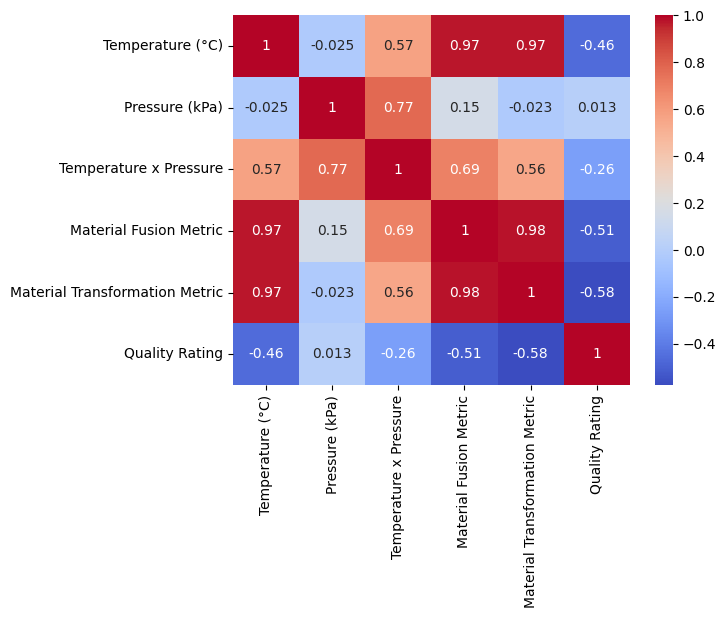

In [17]:
sns.heatmap(corr,annot=True,cmap="coolwarm")

<Axes: xlabel='Quality Rating', ylabel='Count'>

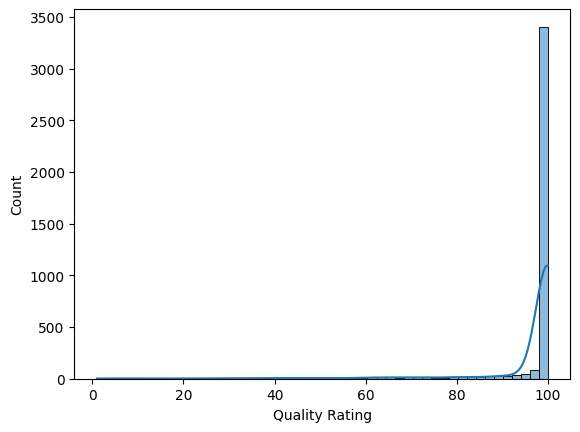

In [16]:
sns.histplot(data=df,x="Quality Rating",kde=True,bins=50)

<Axes: xlabel='Material Fusion Metric', ylabel='Quality Rating'>

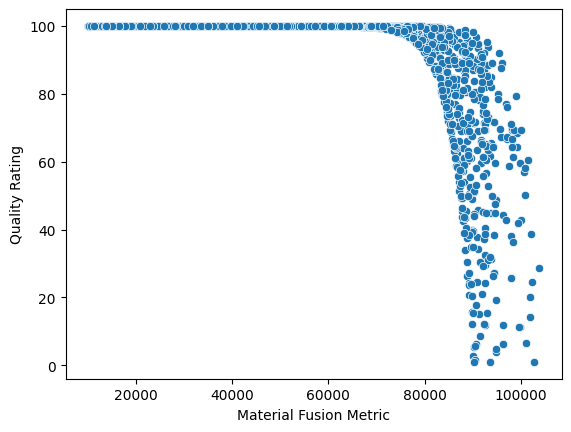

In [21]:
sns.scatterplot(data=df,x="Material Fusion Metric",y="Quality Rating")

<Axes: xlabel='Material Transformation Metric', ylabel='Quality Rating'>

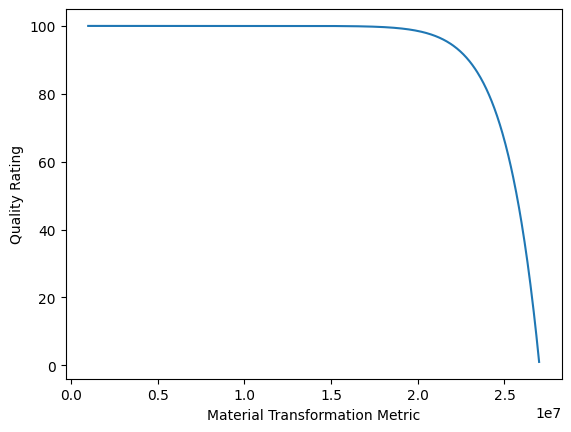

In [22]:
sns.lineplot(data=df,x="Material Transformation Metric",y="Quality Rating")

<Axes: xlabel='Temperature x Pressure', ylabel='Quality Rating'>

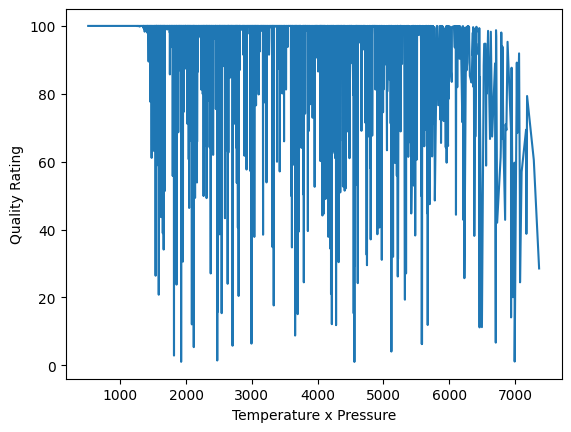

In [25]:
sns.lineplot(data=df,x="Temperature x Pressure",y="Quality Rating")

In [26]:
x=df.drop(columns=["Quality Rating","Pressure (kPa)"])
y=df["Quality Rating"]

In [27]:
x.shape

(3957, 4)

In [28]:
y.shape

(3957,)

In [55]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.metrics import r2_score,mean_squared_error,mean_absolute_error

In [31]:
x_train,x_test,y_train,y_test=train_test_split(x,y,test_size=0.2,random_state=42)

In [33]:
model=LinearRegression()

In [34]:
model.fit(x_train,y_train)

LinearRegression()

In [35]:
pred=model.predict(x_test)

In [58]:
r2_score_result=r2_score(y_test,pred)
print("r2_score =",r2_score_result)
mean_squared_error_result=mean_squared_error(y_test,pred)
print("mean_squared_error_result =",mean_squared_error_result)
mean_absolute_error_result=mean_absolute_error(y_test,pred)
print("mean_absolute_error_result =",mean_absolute_error_result)
root_mean_squared_error_result=np.sqrt(mean_squared_error_result)
print("root_mean_squared_error_result =",root_mean_squared_error_result)

r2_score = 0.5135657700507026
mean_squared_error_result = 99.30584339515043
mean_absolute_error_result = 5.716539983048446
root_mean_squared_error_result = 9.965231728121049


In [46]:
from sklearn.preprocessing import PolynomialFeatures


In [47]:
poly=PolynomialFeatures(degree=2)

In [48]:
x_train_poly=poly.fit_transform(x_train)
x_test_ploy=poly.transform(x_test)


In [49]:
model_poly=LinearRegression()

In [50]:
model_poly.fit(x_train_poly,y_train)

LinearRegression()

In [51]:
poly_pred=model_poly.predict(x_test_ploy)

In [60]:

poly_r2_score_result=r2_score(y_test,poly_pred)
print("poly_r2_score =",poly_r2_score_result)
poly_mean_squared_error_result=mean_squared_error(y_test,poly_pred)
print("poly_mean_squared_error_result =",poly_mean_squared_error_result)
poly_mean_absolute_error_result=mean_absolute_error(y_test,poly_pred)
print("poly_mean_absolute_error_result =",poly_mean_absolute_error_result)
poly_root_mean_squared_error_result=np.sqrt(poly_mean_squared_error_result)
print("poly_root_mean_squared_error_result =",poly_root_mean_squared_error_result)

poly_r2_score = 0.9265354175510244
poly_mean_squared_error_result = 14.99783911286119
poly_mean_absolute_error_result = 2.5114048419811894
poly_root_mean_squared_error_result = 3.8727043668296175


In [61]:

test_data = pd.DataFrame({
    "Temperature (°C)": [209.762701, 243.037873, 220.552675],
    "Temperature x Pressure": [1688.769167, 3842.931469, 1729.823314],
    "Material Fusion Metric": [44522.217074, 63020.764997, 49125.950249],
    "Material Transformation Metric": [
        9229576, 14355370, 10728390
    ]
})


test_data_poly = poly.transform(test_data)


predictions = model_poly.predict(test_data_poly)

test_data["Predicted Quality Rating"] = predictions

print(test_data[["Predicted Quality Rating"]])


   Predicted Quality Rating
0                 97.271007
1                100.973134
2                 97.676633
